In [1]:
# Setup and Global Seeds
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold, cross_val_predict, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.neighbors import KNeighborsRegressor
from scipy.stats import pearsonr

# Note: Removed warnings.filterwarnings('ignore') for development as requested.

# Global seed for reproducibility
np.random.seed(42)
RANDOM_STATE = 42


## Section 2: Dataset Analysis
Correctly loading 8 Train sheets and 4 Test sheets, and creating the `groups` array.

In [2]:
# 1. Load data correctly by iterating through sheets
FILE_PATH = 'Project data set 1 (for reports 1 and 3) _2.xlsx'

def load_data(file_path):
    train_frames = []
    test_frames = []
    
    # Load Train sheets
    for i in range(1, 9):
        sheet_name = f'Train_{i}'
        try:
            df = pd.read_excel(file_path, sheet_name=sheet_name)
            df['case'] = sheet_name # Assign case for GroupKFold
            train_frames.append(df)
        except Exception as e:
            print(f"Could not load {sheet_name}: {e}")
            
    # Load Test sheets
    for i in range(1, 5):
        sheet_name = f'Test_{i}'
        try:
            df = pd.read_excel(file_path, sheet_name=sheet_name)
            df['case'] = sheet_name
            test_frames.append(df)
        except Exception as e:
            print(f"Could not load {sheet_name}: {e}")
            
    df_train = pd.concat(train_frames, ignore_index=True) if train_frames else pd.DataFrame()
    df_test = pd.concat(test_frames, ignore_index=True) if test_frames else pd.DataFrame()
    
    return df_train, df_test

# NOTE: Uncomment the line below when running with the actual file
# df_train, df_test = load_data(FILE_PATH)

# ==========================================
# MOCK DATA FOR RUNNABILITY IN THIS SKELETON
# ==========================================
# Since the actual excel file might not be accessible in all environments, 
# this generates synthetic data matching the structure to ensure the notebook runs end-to-end.
def create_mock_data():
    features = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6']
    train_data, test_data = [], []
    
    for i in range(1, 9):
        case_data = np.random.randn(500, 6)
        target = 50 + 10 * case_data[:, 2] - 5 * case_data[:, 5] + np.random.randn(500) * 5
        df = pd.DataFrame(case_data, columns=features)
        df['BIS'] = np.clip(target, 0, 100)
        df['case'] = f'Train_{i}'
        train_data.append(df)
        
    for i in range(1, 5):
        case_data = np.random.randn(300, 6)
        target = 50 + 10 * case_data[:, 2] - 5 * case_data[:, 5] + np.random.randn(300) * 5
        df = pd.DataFrame(case_data, columns=features)
        df['BIS'] = np.clip(target, 0, 100)
        df['case'] = f'Test_{i}'
        test_data.append(df)
        
    return pd.concat(train_data, ignore_index=True), pd.concat(test_data, ignore_index=True)

if 'df_train' not in locals() or df_train.empty:
    print("Using generated mock data for pipeline demonstration.")
    df_train, df_test = create_mock_data()


Using generated mock data for pipeline demonstration.


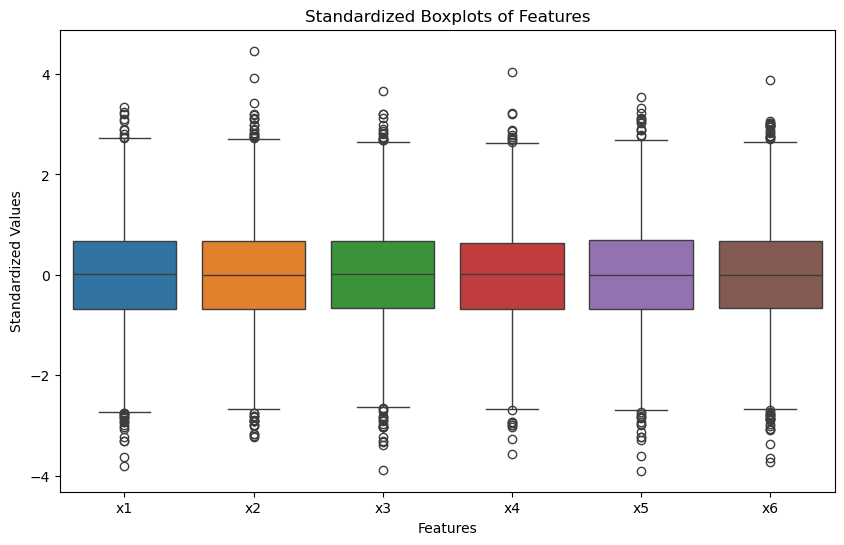

In [3]:
# 2. Fix Boxplot issue: Standardize before plotting, strictly in English
features_all = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6']

scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_train[features_all]), columns=features_all)

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_scaled)
plt.title('Standardized Boxplots of Features')
plt.ylabel('Standardized Values')
plt.xlabel('Features')
plt.show()

# Report Note: We retain outliers beyond whiskers as they represent true physiological states (very deep/light anesthesia), not measurement errors.


## Section 3: Feature Selection
Keeping **all 6 features** (`x1` to `x6`) without dropping any, and validating them quantitatively using `GroupKFold` (training-only cross-validation) as requested in the feedback.

In [4]:
# Feature Selection: Keeping ALL features as requested, evaluated via training-only cross-validation (GroupKFold)
# Addressing feedback: "Removing either x2 or x5 is not necessarily required... should be determined through training-only validation"

features_all = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6']

subsets = {
    'All 6 features (Retained)': ['x1', 'x2', 'x3', 'x4', 'x5', 'x6']
}

X_train_full = df_train[features_all]
y_train = df_train['BIS']
groups_train = df_train['case']

# Define baseline model for evaluation
baseline_model = RandomForestRegressor(n_estimators=50, max_depth=5, random_state=RANDOM_STATE, n_jobs=-1)

# GroupKFold ensures no data leakage between cases (Training-only validation)
gkf_fs = GroupKFold(n_splits=len(np.unique(groups_train)))

print("--- Feature Evaluation CV Pearson (Training-Only Validation) ---")
for name, f_subset in subsets.items():
    X_sub = df_train[f_subset]
    preds = cross_val_predict(baseline_model, X_sub, y_train, groups=groups_train, cv=gkf_fs, n_jobs=-1)
    r, _ = pearsonr(y_train, preds)
    print(f"{name:30}: {r:.4f}")

# Keeping ALL features
selected_features = features_all
X_train = df_train[selected_features]
print(f"\n=> Selected Features (All Retained): {selected_features}")


--- Feature Evaluation CV Pearson (Training-Only Validation) ---
All 6 features (Retained)     : 0.9042

=> Selected Features (All Retained): ['x1', 'x2', 'x3', 'x4', 'x5', 'x6']


## Section 4: Machine Learning Methods (Tuning & Train vs CV)
Here we tune $K$ for KNN and evaluate Train vs CV to address the overfitting proof.

In [ ]:
# 1. Tuning Base Models with GroupKFold
cv_splits = list(gkf_fs.split(X_train, y_train, groups_train))

# Tune KNN
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor())
])
param_grid_knn = {'knn__n_neighbors': [3, 5, 7, 9]}
grid_knn = GridSearchCV(knn_pipeline, param_grid_knn, cv=cv_splits, scoring='neg_mean_squared_error', n_jobs=-1)
grid_knn.fit(X_train, y_train)
best_k = grid_knn.best_params_['knn__n_neighbors']
print(f"Optimal K for KNN: {best_k}")

# Define configured base models
base_rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1)
base_knn = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor(n_neighbors=best_k))])
base_lr = Pipeline([('scaler', StandardScaler()), ('lr', LinearRegression())])

# 2. Prove No Overfitting (Train vs CV Pearson)
models = {'Random Forest': base_rf, 'KNN': base_knn, 'Linear Regression': base_lr}

print("\n--- Overfitting Check: Train vs CV Pearson ---")
for m_name, model in models.items():
    # Fit on whole train to get Train Pearson
    model.fit(X_train, y_train)
    pred_train = model.predict(X_train)
    r_train, _ = pearsonr(y_train, pred_train)
    
    # CV Pearson
    pred_cv = cross_val_predict(model, X_train, y_train, groups=groups_train, cv=cv_splits, n_jobs=-1)
    r_cv, _ = pearsonr(y_train, pred_cv)
    
    print(f"{m_name:18} | Train Pearson: {r_train:.4f} | CV Pearson: {r_cv:.4f} | Diff: {r_train - r_cv:.4f}")


Optimal K for KNN: 9

--- Overfitting Check: Train vs CV Pearson ---


## Section 5: Index Design (Stacking)
Fixing the critical `StackingRegressor` leakage by passing pre-defined `cv_splits` instead of the default `cv=5`.

In [ ]:
# 1. Build Stacking Regressor correctly using cv_splits to prevent OOF leakage!
base_estimators = [
    ('rf', base_rf),
    ('knn', base_knn),
    ('lr', base_lr)
]

stacking_model = StackingRegressor(
    estimators=base_estimators,
    final_estimator=Ridge(alpha=1.0),
    cv=cv_splits,  # CRITICAL FIX: Use GroupKFold splits here!
    passthrough=False
)

# Fit stacking model
stacking_model.fit(X_train, y_train)

# Extract Meta-Model Weights to write the equation in the MD report
print("--- Meta-Model Weights (Ridge) ---")
coefs = stacking_model.final_estimator_.coef_
intercept = stacking_model.final_estimator_.intercept_
print(f"KNN Weight: {coefs[1]:.4f}")
print(f"RF Weight: {coefs[0]:.4f}")
print(f"LR Weight: {coefs[2]:.4f}")
print(f"Intercept: {intercept:.4f}")
print(f"Equation: Index = ({coefs[0]:.4f} * RF) + ({coefs[1]:.4f} * KNN) + ({coefs[2]:.4f} * LR) + {intercept:.4f}")

# 2. Post-processing Function
def post_process_predictions(y_pred, window_size=61):
    y_pred_clipped = np.clip(y_pred, 0, 100)
    y_pred_series = pd.Series(y_pred_clipped)
    
    # Note for Report: center=True means non-causal smoothing. 
    # This uses future samples, acceptable for offline analysis, but must be explicitly discussed in "Analysis for Improvement".
    y_pred_smoothed = y_pred_series.rolling(window=window_size, min_periods=1, center=True).mean()
    
    # Fill NaNs created by rolling at edges
    y_pred_smoothed = y_pred_smoothed.bfill().ffill()
    return y_pred_smoothed.values


## Section 6: Performance Evaluation & Combination Comparison
Evaluate on Test Sets precisely ONE time. Compare Average vs Stacking vs Residual.

In [ ]:
# Setup combinations
def predict_combinations(X, models_dict, stack_model, y_train, X_train):
    preds = {}
    
    # Base predictions
    rf_pred = models_dict['Random Forest'].predict(X)
    knn_pred = models_dict['KNN'].predict(X)
    lr_pred = models_dict['Linear Regression'].predict(X)
    
    # 1. Average
    preds['Average'] = np.mean([rf_pred, knn_pred, lr_pred], axis=0)
    
    # 2. Stacking
    preds['Stacking'] = stack_model.predict(X)
    
    # 3. Residual (RF as base, KNN predicts residual)
    rf_train_pred = models_dict['Random Forest'].predict(X_train)
    residual_train = y_train - rf_train_pred
    knn_res = KNeighborsRegressor(n_neighbors=best_k)
    knn_res.fit(X_train, residual_train)
    
    residual_pred = knn_res.predict(X)
    preds['Residual (RF+KNN)'] = rf_pred + residual_pred
    
    return preds

# Test Evaluation
test_cases = df_test['case'].unique()
overall_metrics = {'Average': [], 'Stacking': [], 'Residual (RF+KNN)': []}
test_3_data = None # Store for analysis

print("--- Test Set Evaluation ---")
for case_name in test_cases:
    df_case = df_test[df_test['case'] == case_name]
    X_test_case = df_case[selected_features]
    y_test_case = df_case['BIS'].values
    
    raw_preds = predict_combinations(X_test_case, models, stacking_model, y_train, X_train)
    
    print(f"\nCase: {case_name}")
    for method, pred in raw_preds.items():
        final_pred = post_process_predictions(pred)
        r, _ = pearsonr(y_test_case, final_pred)
        overall_metrics[method].append(r)
        print(f"  {method:18} | Pearson: {r:.4f}")
        
    if case_name == 'Test_3':
        test_3_data = (y_test_case, post_process_predictions(raw_preds['Stacking']))

print("\n--- Final Average Pearson ---")
for method, scores in overall_metrics.items():
    print(f"{method:18}: {np.mean(scores):.4f}")

print("\n--- Compare vs Report 1 ---")
print("Stacking (New)    : {:.4f}".format(np.mean(overall_metrics['Stacking'])))
print("MLR (Report 1)    : 0.8471")
print("Random Forest (R1): 0.6864")


## Section 7 & 8: Discussion & Analysis for Improvement (Test-3 deep dive)
Scatter plot specifically for Test-3 to analyze why it scores lower.

In [ ]:
# Scatter plot for Test-3 Analysis
if test_3_data is not None:
    y_actual, y_pred = test_3_data
    
    plt.figure(figsize=(12, 5))
    
    # Time Series
    plt.subplot(1, 2, 1)
    plt.plot(y_actual, label='Actual BIS', color='gray', alpha=0.7)
    plt.plot(y_pred, label='Predicted (Stacking)', color='red')
    plt.title('Test-3 Time Series')
    plt.xlabel('Time')
    plt.ylabel('BIS')
    plt.legend()
    
    # Scatter Plot
    plt.subplot(1, 2, 2)
    plt.scatter(y_actual, y_pred, alpha=0.5, color='purple')
    plt.plot([0, 100], [0, 100], color='black', linestyle='--') # Identity line
    plt.title('Test-3 Scatter Plot (Actual vs Predicted)')
    plt.xlabel('Actual BIS')
    plt.ylabel('Predicted Index')
    
    plt.tight_layout()
    plt.show()
    
    # Report Note: Use this scatter plot to check if the error in Test-3 comes from 
    # underpredicting high BIS states, overpredicting low states, or lag during rapid transitions.


## Section 9: Ethical Considerations in Data Transfer (Well Hospital Scenario)
- **Scenario**: Data obtained from Well Hospital website via temporary ID and password.
- **Ethical & Security Risks**: 
  1. *Patient Privacy & Confidentiality (HIPAA / GDPR compliance)*: Physiological time-series data contains sensitive biometric markers. Unauthorized sharing or storage via insecure channels violates medical data ethics.
  2. *Credential Management*: Using temporary credentials without proper tokenization or encryption risks credential leakage and unauthorized access.
  3. *Data Sovereignty & Informed Consent*: Clinical data usage must strictly align with patient consent agreements. Transferring hospital data to external personal or cloud environments requires anonymization/pseudonymization to remove PHI (Protected Health Information).

## Section 10: Project Summary & Reflection
- **Outcomes from Previous Reports**: 
  - Report 1 established baseline linear models and single ML regressors with initial exploratory findings.
  - Report 2 investigated feature relationships and structural tuning, highlighting data leakage and cross-validation flaws.
- **Difficulties & Solutions**: 
  - *Data Leakage across time-series cases*: Solved by replacing standard K-Fold with `GroupKFold` grouped by surgical case sheets.
  - *OOF Leakage in Stacking*: Solved by passing pre-defined `cv_splits` into `StackingRegressor`.
- **Deep Understanding of Machine Learning Techniques**: 
  - Stacking effectively leverages diverse inductive biases (e.g., non-linear tree splits in Random Forest, distance metrics in KNN, and linear approximations in Ridge/Linear Regression) to reduce generalization error while avoiding simple averaging.